# Capítulo 6 · LLM y aprendizaje por refuerzo

**Lectura:** pp. 147–172; §§6.1–6.4. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch6).

**Idea central:** RL puede mejorar un modelo de lenguaje, y un modelo de lenguaje puede aportar representaciones, recompensas, modelos o políticas a un sistema de RL. Son dos direcciones diferentes.

## Resumen

§6.2 distingue preentrenamiento, ajuste supervisado y ajuste con recompensas. SFT aprende de respuestas demostradas; RLFT favorece respuestas que obtiene buenas puntuaciones al generarlas. Verificar a veces es más sencillo que producir una solución. RLVR usa señales verificables; RLHF aprende recompensas a partir de preferencias humanas; RLAIF usa evaluaciones de otros modelos. Las recompensas de resultado evalúan el final; las de proceso ofrecen información intermedia, pero pueden ser más difíciles de especificar o aprender.

El capítulo conecta la generación de tokens intermedios con cómputo adicional antes de responder. Discute qué capacidades aporta el modelo base y cuáles puede potenciar RL; no conviene interpretar automáticamente mejoras como aparición de capacidades desde cero. También separa un sistema de módulos con un objetivo común de un juego donde varios agentes persiguen objetivos propios.

En una interacción de un solo turno, el prompt puede ser contexto y la respuesta completa una acción: un bandit contextual. Si desplegamos la generación token a token, el estado es el prefijo. PPO, GRPO, DAPO, GSPO, RLOO y REINFORCE++ difieren en cómo estiman ventajas, normalizan, recortan razones de probabilidad o agregan pérdidas. GRPO estima una referencia con respuestas del mismo prompt; RLOO excluye la recompensa de la propia muestra al calcular su baseline. Esto permite prescindir de un crítico, pero requiere suficientes muestras y puede aumentar el coste.

La regularización KL intenta evitar cambios excesivos respecto al modelo de referencia. DPO conecta la solución del problema regularizado con un modelo de preferencias y optimiza pares preferido/rechazado directamente. Es una formulación distinta de un bucle online de política y recompensa. El muestreo guiado en inferencia y el ajuste con RL también pueden entenderse como maneras de aproximar una distribución favorecida por la recompensa, pagando el cómputo en momentos diferentes.

En problemas de varios turnos, acciones como herramientas y respuestas afectan a un entorno externo. Surgen consecuencias retrasadas, estados ocultos, acciones inválidas y contextos crecientes. El retorno y el crédito deben asignarse a través de la interacción. RAGEN, entrenamiento por turnos y métodos con críticos abordan partes del problema. La discusión de alineamiento y juegos de asistencia destaca que la utilidad humana puede ser incierta; optimizar un proxy fijo no elimina esa incertidumbre.

§6.3 invierte la dirección: usa LLM para interpretar observaciones, proponer recompensas, generar modelos del mundo, producir acciones o escribir código que implemente modelos y políticas. Generar un programa reutilizable puede ser mucho más rápido que llamar al modelo en cada paso, pero su corrección debe comprobarse. La latencia y el tamaño del contexto importan; se mencionan alternativas recurrentes y arquitecturas híbridas.

§6.4 muestra un ciclo de entrenamiento con Tinker y GEM: recoger episodios, calcular retornos y ventajas, preparar pérdidas por token, actualizar y registrar estabilidad. Los tokens del entorno no son decisiones del agente y se enmascaran. El ejemplo del libro usa servicios de entrenamiento; nuestro laboratorio es una reducción local y no reproduce esa infraestructura.

## Ecuaciones esenciales

Para una respuesta $y$ a un prompt $x$,

$$
J(\pi)=\mathbb{E}_{y\sim\pi(\cdot|x)}[r(x,y)]
-\beta D_{\mathrm{KL}}(\pi(\cdot|x)\|\pi_{\mathrm{ref}}(\cdot|x)).
$$

Si $\beta>0$, hay soporte apropiado y podemos representar cualquier distribución, la solución es

$$
\pi^*(y|x)=
\frac{\pi_{\mathrm{ref}}(y|x)\exp(r(x,y)/\beta)}
{\sum_{y'}\pi_{\mathrm{ref}}(y'|x)\exp(r(x,y')/\beta)}.
$$

Para un grupo de $K>1$ respuestas independientes, RLOO usa $b_i=\frac{1}{K-1}\sum_{j\ne i}r_j$. La recompensa de la propia muestra no entra en su baseline.

## Experimento 6 · Optimizar el proxy equivocado

**Pregunta:** ¿puede mejorar la recompensa mientras empeora la respuesta real?

Un único prompt tiene cuatro respuestas posibles:

| Respuesta | Probabilidad inicial | Recompensa real | Recompensa proxy |
|---|---:|---:|---:|
| Correcta breve | 0.5 | 1 | 1 |
| Correcta larga | 0.2 | 1 | 1.2 |
| Incorrecta convincente | 0.1 | 0 | 1.8 |
| Irrelevante | 0.2 | 0 | −0.2 |

Entrenamos logits categóricos con RLOO y penalización KL. Comparamos cuatro coeficientes sobre el proxy, $\beta=0,0.1,0.5,2$, y un control que optimiza la recompensa real con $\beta=0.1$.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 6
~~~

**Métricas:** recompensa proxy esperada, probabilidad de corrección y KL respecto a la referencia. Hay 800 actualizaciones de 64 muestras y 20 semillas. Guardamos también el óptimo analítico: el entrenamiento con presupuesto finito no tiene por qué alcanzarlo.

**Resultado observado:** sin KL, la corrección cae desde 70% hasta aproximadamente 0.78%, aunque el proxy mejora. Una KL fuerte reduce el desplazamiento, pero no corrige la preferencia equivocada del proxy. Optimizar el verificador lleva la corrección a aproximadamente 98.7%.

**Modificación:** intercambia la puntuación proxy de una respuesta correcta y la incorrecta, o cambia las probabilidades iniciales. Observa cómo cambian la solución analítica y la velocidad de aprendizaje.

**Límite:** es una distribución sobre cuatro respuestas fijas; no hay transformer, tokens, generalización entre prompts ni entrenamiento de un reward model. Ilustra RLOO, KL y mala especificación, no mide el comportamiento de un LLM real.



## Para el grupo

1. ¿Qué diferencia hay entre un verificador correcto y uno que solo cubre algunos casos?
2. ¿Por qué una penalización KL no garantiza alineamiento?
3. ¿Cuándo deja de ser suficiente el modelo de bandit de un solo turno?

**Conexión:** la cobertura de datos, la exploración y el cambio de distribución llevan al capítulo 7.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 6
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 6: respuestas categóricas, RLOO, KL y reward hacking; NO es un LLM."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import softmax, guardar, curva, filas_finales, resumen_muestra

REFERENCIA = np.array([.5, .2, .1, .2])
REAL = np.array([1., 1., 0., 0.])
PROXY = np.array([1., 1.2, 1.8, -.2])

def objetivo(theta, reward, beta):
    p = softmax(theta)
    return float(p@reward - beta*np.sum(p*np.log(p/REFERENCIA)))

def gradiente_exacto(theta, reward, beta):
    p = softmax(theta)
    utility = reward - beta*(np.log(p/REFERENCIA)+1)
    return p*(utility-p@utility)

def entrenar(seed, beta, reward, pasos=800, batch=64):
    rng = np.random.default_rng(seed)
    theta = np.log(REFERENCIA).copy()
    history = []
    for t in range(pasos+1):
        p = softmax(theta)
        history.append([p@PROXY, p@REAL, np.sum(p*np.log(p/REFERENCIA))])
        if t == pasos:
            break
        a = rng.choice(4, batch, p=p)
        rewards = reward[a]
        # Cada baseline excluye la recompensa de la acción que multiplica.
        loo = (rewards.sum()-rewards)/(batch-1)
        signal = rewards-loo-beta*np.log(p[a]/REFERENCIA[a])
        grad = np.mean(signal[:, None]*(np.eye(4)[a]-p), axis=0)
        theta += .15*grad
    return np.array(history), softmax(theta)

def ejecutar(out, seed=2026, replicas=20):
    cases = [("Proxy β=0", 0., PROXY), ("Proxy β=0.1", .1, PROXY),
             ("Proxy β=0.5", .5, PROXY), ("Proxy β=2", 2., PROXY),
             ("Verificador β=0.1", .1, REAL)]
    arrays, rows, metrics = {}, [], {"iteraciones": 800, "batch": 64, "learning_rate": .15,
                                   "referencia": REFERENCIA.tolist(), "recompensa_real": REAL.tolist(),
                                   "recompensa_proxy": PROXY.tolist()}
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for name, beta, reward in cases:
        data = [entrenar(seed+k, beta, reward) for k in range(replicas)]
        h = np.array([d[0] for d in data])
        final_p = np.array([d[1] for d in data])
        arrays[name], arrays[name+" probabilidades"] = h, final_p
        for j in range(3):
            curva(ax[j], np.arange(h.shape[1])*64, h[:, :, j], name)
        optimum = softmax(np.log(REFERENCIA)+reward/beta) if beta else np.eye(4)[reward.argmax()]
        metrics[name] = {"acierto_final": resumen_muestra(h[:, -1, 1]),
                         "proxy_final": resumen_muestra(h[:, -1, 0]),
                         "kl_final": resumen_muestra(h[:, -1, 2]),
                         "probabilidades_finales_medias": final_p.mean(axis=0).tolist(),
                         "optimo_analitico": optimum.tolist()}
        rows += filas_finales(name, h[:, -1, 1])
    for axis, ylabel in zip(ax, ["Recompensa proxy esperada", "Probabilidad de respuesta correcta", "KL(π || π referencia)"]):
        axis.set(xlabel="Respuestas muestreadas", ylabel=ylabel)
    ax[1].set_ylim(0, 1)
    ax[0].legend(fontsize=8)
    return guardar(out, arrays, rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 6: completado en 2.07 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap06



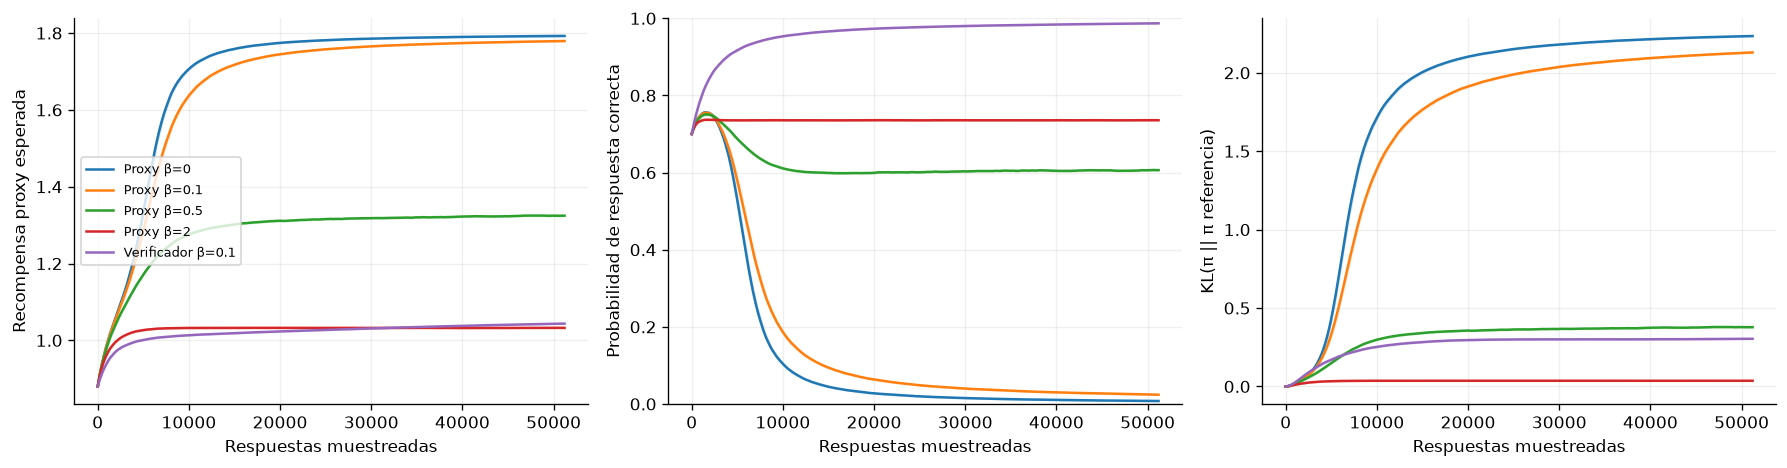

{
  "iteraciones": 800,
  "batch": 64,
  "learning_rate": 0.15,
  "referencia": [
    0.5,
    0.2,
    0.1,
    0.2
  ],
  "recompensa_real": [
    1.0,
    1.0,
    0.0,
    0.0
  ],
  "recompensa_proxy": [
    1.0,
    1.2,
    1.8,
    -0.2
  ],
  "Proxy β=0": {
    "acierto_final": {
      "media": 0.00782135745602173,
      "ic95_aprox_semianchura": 0.0001397891853286285
    },
    "proxy_final": {
      "media": 1.7925979134881378,
      "ic95_aprox_semianchura": 0.00015242104995006082
    },
    "kl_final": {
      "media": 2.23423360095065,
      "ic95_aprox_semianchura": 0.0011191890603044498
    },
    "probabilidades_finales_medias": [
      0.0034904154052018826,
      0.0043309420508198465,
      0.991173048065374,
      0.0010055944786044216
    ],
    "optimo_analitico": [
      0.0,
      0.0,
      1.0,
      0.0
    ]
  },
  "Proxy β=0.1": {
    "acierto_final": {
      "media": 0.024153414519545356,
      "ic95_aprox_semianchura": 0.00039863874198079445
    },
    "

In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

Proxy β=0 (20, 801, 3)
Proxy β=0 probabilidades (20, 4)
Proxy β=0.1 (20, 801, 3)
Proxy β=0.1 probabilidades (20, 4)
Proxy β=0.5 (20, 801, 3)
Proxy β=0.5 probabilidades (20, 4)
Proxy β=2 (20, 801, 3)
Proxy β=2 probabilidades (20, 4)
Verificador β=0.1 (20, 801, 3)
Verificador β=0.1 probabilidades (20, 4)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.